<a href="https://colab.research.google.com/github/poojagupthaa14/OIBSIP/blob/main/pooja_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [6]:
df = pd.read_csv('train.csv')

In [7]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.shape

(891, 12)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [11]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [12]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [13]:
(df.isnull().sum() / len(df)) * 100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


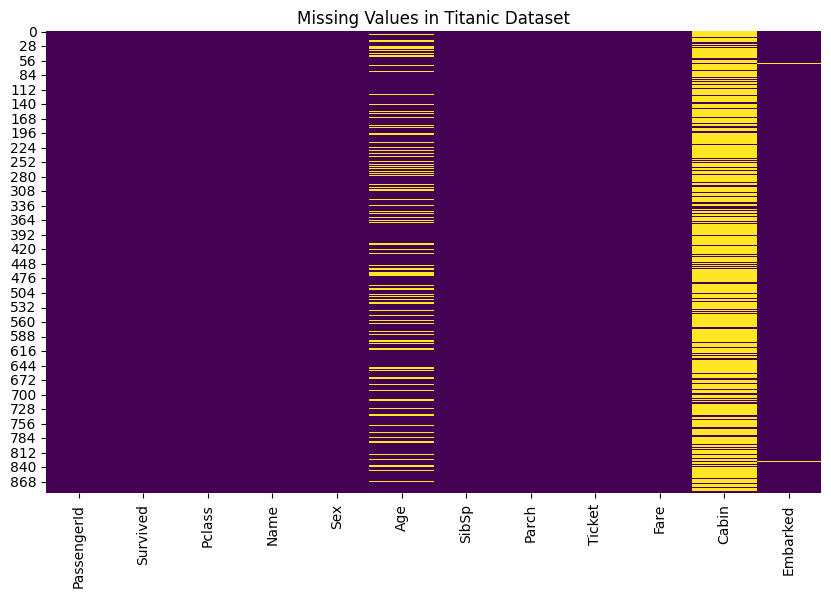

In [14]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values in Titanic Dataset')
plt.show()

**Observation:**

The heatmap shows the distribution of missing values in the Titanic dataset. The Cabin column contains the highest number of missing values, followed by the Age column. The Embarked column has very few missing values, while most other columns contain complete information. This visualization helps identify columns that require data cleaning before further analysis.

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df[df.duplicated()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [17]:
df.drop_duplicates(inplace=True)

In [18]:
df.duplicated().sum()

np.int64(0)

**Observation:**

Duplicate records were checked in the Titanic dataset using the duplicated() function. Duplicate rows, if present, were identified and removed using drop_duplicates(). This helps maintain data consistency and prevents repeated records from affecting further analysis.

In [19]:
df.select_dtypes(include=np.number).columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

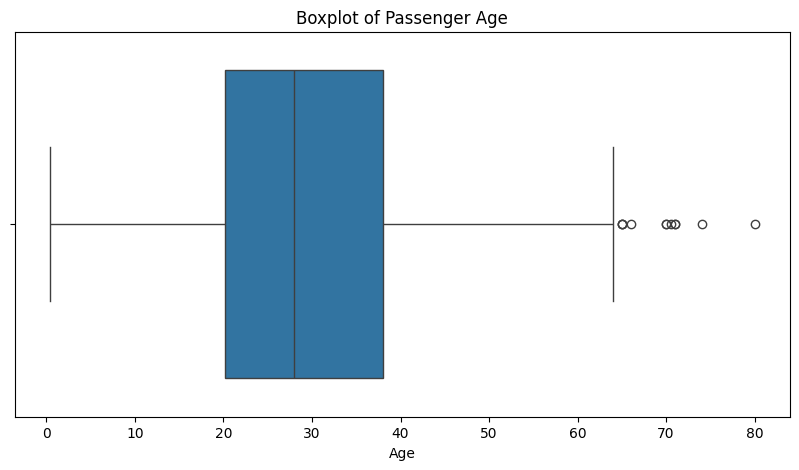

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Age'])

plt.title('Boxplot of Passenger Age')
plt.xlabel('Age')

plt.show()

**Observation:**

The boxplot shows the distribution of passenger ages in the Titanic dataset. Most passengers are between approximately 20 and 38 years old, with a median age of around 28 years. A few values above 65 years are identified as potential outliers. This indicates that the age distribution contains some unusually high values compared to the majority of passengers.

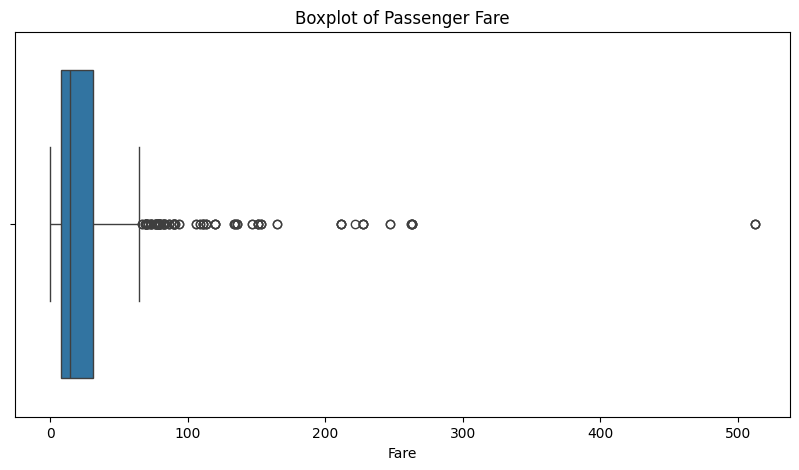

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Fare'])

plt.title('Boxplot of Passenger Fare')
plt.xlabel('Fare')

plt.show()

**Observation:**

The boxplot shows the distribution of passenger fares in the Titanic dataset. Most passengers paid relatively low fares, while a smaller number paid significantly higher amounts. Several potential outliers can be observed beyond the upper whisker, including an extreme value around 512. The distribution is highly right-skewed, indicating that a few passengers paid much higher fares than the majority.

In [22]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [24]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df.shape

(891, 12)

In [27]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [32]:
# Fill missing Age values
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked values
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Remove Cabin column
df.drop('Cabin', axis=1, inplace=True)

In [33]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Duplicate Records:
0

Dataset Shape:
(891, 11)


In [34]:
df.to_csv('cleaned_titanic.csv', index=False)

In [35]:
from google.colab import files

files.download('cleaned_titanic.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Overall Observations

1. The Titanic dataset initially contained 891 rows and 12 columns.

2. Missing values were identified in the Age, Cabin and Embarked columns.

3. The Age column contained 177 missing values, which were filled using the median.

4. The Embarked column contained 2 missing values, which were filled using the mode.

5. The Cabin column contained 687 missing values and was removed because of the large amount of incomplete data.

6. Duplicate records were checked, and no duplicate rows were found.

7. Boxplots revealed potential outliers in both Age and Fare columns.

8. The Fare column showed several unusually high values, indicating a right-skewed distribution.

9. Genuine outliers were retained because they may represent actual passenger information.

10. Finally, the dataset was validated and saved as a cleaned CSV file.

### Conclusion

The Titanic dataset was successfully cleaned using Python libraries such as Pandas, NumPy, Matplotlib and Seaborn.

The cleaning process involved identifying and handling missing values, checking duplicate records, analyzing outliers and examining data types. Missing numerical values were handled using median imputation, while categorical missing values were filled using mode imputation. The Cabin column was removed due to its large number of missing values.

Visualizations such as heatmaps and boxplots helped identify missing values and potential outliers. Genuine outliers were retained to preserve meaningful information.

Finally, the cleaned dataset was validated and exported into CSV format.

Through this task, I gained practical experience in data cleaning, data validation and exploratory data analysis using Python.